# ICT-01 — Universel, fragile : la consécration du substrat témoin

> **Série ICT** (Integrated Causal Trajectories) — capstone de la **strate 0**. Le Jeu de la Vie de Conway (règle **B3/S23**) est le *substrat témoin* de la série : le support de calcul sur lequel toute mesure des strates suivantes s'effectue. Ce carnet le consacre en consacrant **ses deux propriétés fondatrices** — l'une **citée** (il est Turing-complet, mais ce carnet ne re-prouve pas ce théorème), l'autre **mesurée** (ses formes utiles sont d'une extrême fragilité) — et en **re-mesurant** le certificat qui fonde l'une et l'autre.

Trois visages, trois statuts épistémiques distincts, et c'est le sujet du carnet :

| Face | Statut | Où elle est établie |
|---|---|---|
| **Certifié** | *prouvé* | Pont Lean `evolveHashlifeFastAtN_correct_uncond` : film Hashlife = film naïf, sans hypothèse (section 2, re-mesurée ici) |
| **Universel** | *cité* | Théorème (Cook 2004 pour la règle 110 ; constructions GOL) — jamais re-prouvé ici (section 3) |
| **Fragile** | *mesuré* | Batterie de collisions et bruit macro d'ICT-33, consommés ici (section 4) |

**Plan** :

1. Pourquoi la strate 0 — le substrat avant toute abstraction ;
2. Le **certificat re-mesuré** — calibration canonique et pont Lean, vérifiés par les organes du dépôt ;
3. **L'universalité, citée et située** — ce que le théorème dit, ce que le carnet mesure à côté (le glider comme particule d'information) ;
4. **La fragilité, mesurée** — le contraste des collisions : mêmes masses, destins opposés ;
5. La **lecture émergence** sur le substrat certifié (consomme ICT-32) ;
6. Le **témoin parmi les substrats** — pourquoi le GOL et pas un autre (consomme ICT-31) ;
7. Synthèse — les trois faces du témoin, et la suite de la série.

**Modules** : `ict/life.py`, `ict/causal_emergence.py`. **Notebook pédagogique** : des exercices jalonnent le texte.

**Navigation** : [Index](README.md) | Suivant dans la série : [ICT-1 — Trajectoires de $\Phi$](ICT-01-PhiTrajectories-Python.ipynb) · Parents de la strate : [ICT-Life](ICT-Life-SubstratCertifie-Python.ipynb) · [ICT-31](ICT-31-ContrasteTroisSubstrats-Python.ipynb) · [ICT-32](ICT-32-StratificationCausaleLife-Python.ipynb) · ICT-33

> **Statut épistémique** — **Sans verdict à ce jour** : la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md) ne concerne pas encore ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

# Les organes de la serie vivent a la racine du depot : on les met sur le
# chemin d'import pour que `ict.life` et `ict.causal_emergence` se chargent
# depuis l'arbre courant (jamais d'installation cachee).
sys.path.insert(0, os.path.abspath("."))

# La serie ICT possede la semantique ; ce carnet la consomme sans la
# reecrire (regle organ-first) :
#   - calibrage canonique du substrat (calibrate_all, CALIBRATION) ;
#   - primitives d'evolution (next_generation, live_cells, embed) ;
#   - mesures glider (period_and_displacement, is_glider, trajectory) ;
#   - batteries de collisions (glider_collision, collision_outcome) ;
#   - generation de densites (random_soup) et pattern canonique.
from ict.life import (
    CALIBRATION,
    calibrate_all,
    canonical_pattern,
    collision_outcome,
    embed,
    glider_collision,
    is_glider,
    live_cells,
    next_generation,
    period_and_displacement,
    random_soup,
    trajectory,
)

print("numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.4.2 | matplotlib 3.11.0


## 1. Pourquoi la strate 0 — le substrat avant toute abstraction

Le cadrage de la série (`ICT-0-Framing`) décritait des strates 1 à 7 : la photographie en mouvement ($\Phi$ le long d'une trajectoire), la morphogenèse, les trajectoires intégrées, la jambe représentationnelle, le LLM comme substrat, l'argumentation, les freebits. La strate 0 ajoute, **avant toutes**, le rang du support de calcul lui-même : le Jeu de la Vie n'est pas un appendix transverse de la série — il est le **substrat témoin** qui ouvre la lecture, celui sur lequel chaque strate suivante viendra mesurer.

Pourquoi consacrer un capstone à un substrat, alors qu'`ICT-Life` le certifie déjà ? Parce que **la consécration demandée porte sur deux propriétés qu'aucun carnet seul n'établit ensemble** : le GOL est Turing-complet (c'est un *théorème* — cité ici avec sa source, jamais re-prouvé) et ses formes utiles sont d'une extrême fragilité (c'est une *mesure* — établie par la batterie de collisions d'ICT-33). La première propriété dit que ce substrat peut porter n'importe quel calcul ; la seconde dit que ce qu'il porte s'effondre à la moindre variation. **Un témoin à la fois tout-puissant et frêle** : c'est cette tension qui fait de lui un instrument exigeant, et non un jouet.

Ce que « témoin » veut dire, mesurablement :

- **certifié** — le film de trajectoire que la série mesure est le même que celui du moteur naïf, **par preuve formelle** (section 2) ;
- **universel** — le substrat peut porter le calcul en général (section 3) ;
- **fragile** — les structures qui portent ce calcul sont sensibles au détail fin (section 4).

Les sections 5 et 6 consomment les deux lectures déjà publiées du substrat — l'émergence causale de Hoel (ICT-32) et le contraste à trois substrats (ICT-31) — pour refermer la strate : le témoin n'est pas seulement certifié et capable, il est déjà **lu** de deux manières indépendantes.

## 2. Le certificat, re-mesuré — calibration canonique et pont Lean

`ICT-Life` a établi le certificat : la calibration canonique (périodes et déplacements des patterns canoniques contre les constantes documentées) et le **pont Lean** — le théorème `evolveHashlifeFastAtN_correct_uncond` garantit que l'évaluation Hashlife (quadtree mémoïsé, sauts $2^k$) produit **le même film** que la simulation naïve pas-à-pas, **sans hypothèse supplémentaire**, tandis que le théorème historique `hashlife_correct` est *vacuously true* dans le régime du saut (son hypothèse `BoxAssezGrand g n` est cappée à $n \le 2$ sur grilles non vides, alors que la garde de saut exige $n \ge \text{jumpSize} \ge 8$ — les deux ensembles sont disjoints).

Un capstone ne **réaffirme** pas un certificat : il le **re-mesure**. Deux gestes, deux organes du dépôt — jamais un comptage artisanal.

In [2]:
# Geste 1 : la calibration canonique, par l'organe ict.life -- cinq verdicts, zero exception.
# CALIBRATION documente les constantes attendues (periode, deplacement) ; calibrate_all
# re-simule chaque pattern canonique et compare. Le certificat n'est pas cite : il est rejoue.
verdicts = calibrate_all()
print(f"{'pattern':<10}{'verdict':>10}")
for nom, ok in sorted(verdicts.items()):
    print(f"{nom:<10}{'OK' if ok else 'ECHEC':>10}")
n_ok = sum(verdicts.values())
print(f"\n{n_ok}/{len(verdicts)} verdicts OK -- attendu : {len(verdicts)}/{len(verdicts)} (CALIBRATION de ict.life)")

pattern      verdict
blinker           OK
block             OK
glider            OK
lwss              OK
pulsar            OK

5/5 verdicts OK -- attendu : 5/5 (CALIBRATION de ict.life)


In [3]:
# Geste 2 : le pont Lean, par l'instrument canonique du depot -- jamais un grep -c sorry artisanal.
# Dans un fichier Lean, le mot "sorry" abonde en PROSE (docstrings, notes de preuve) ; les formes
# reelles (":= by sorry", "exact sorry") ne sont pas des lignes isolees. count_code_sorry retire
# commentaires et docstrings avant de compter ; distinct_code_sorry dedoublonne les miroirs _en.
from pathlib import Path

def _racine_depot(depart):
    for p in [depart, *depart.parents]:
        if (p / "scripts" / "lean" / "count_code_sorry.py").exists():
            return p
    return None

racine = _racine_depot(Path.cwd().resolve())
lake = racine / "MyIA.AI.Notebooks/SymbolicAI/Lean/GOL/conway_lean"
fichier = lake / "Conway/Life/HashlifeCorrectness.lean"

sys.path.insert(0, str(racine / "scripts" / "lean"))
from count_code_sorry import scan_file, scan_lake

_, naifs, reels = scan_file(fichier, racine)
lignes = fichier.read_text(encoding="utf-8").splitlines()
thm = [l.strip() for l in lignes if "theorem evolveHashlifeFastAtN_correct_uncond" in l]

print(f"Fichier : {fichier.relative_to(racine)}")
print(f"sorry naifs (prose comprise) : {naifs}")
print(f"sorry REELS (niveau code)    : {reels}")
for t in thm:
    print("Declaration :", t[:100])

res_lake = scan_lake(lake, racine)
print(f"\nLake conway_lean : distinct_code_sorry = {res_lake.distinct_code_sorry} (le residuel documente intrinseque, #9568, hors chaine du theoreme)")

Fichier : MyIA.AI.Notebooks\SymbolicAI\Lean\GOL\conway_lean\Conway\Life\HashlifeCorrectness.lean


sorry naifs (prose comprise) : 36
sorry REELS (niveau code)    : 0
Declaration : theorem evolveHashlifeFastAtN_correct_uncond (n : Nat) (g : Grid) :



Lake conway_lean : distinct_code_sorry = 1 (le residuel documente intrinseque, #9568, hors chaine du theoreme)


### Lecture du résultat — le certificat tient, et il est vivant

La calibration rejouée rend ses cinq verdicts — blinker, bloc, glider, LWSS, pulsar, attendus aux constantes de `CALIBRATION` — et le fichier `HashlifeCorrectness.lean` ne porte **aucun `sorry` réel au niveau code** : l'écart entre les deux colonnes du second geste est la prose (docstrings, notes de preuve), exactement le piège que l'instrument canonique du dépôt neutralise. À l'échelle du lake, le `sorry` résiduel distinct vit dans `HashlifeMarginFragment.lean` — documenté intrinsèque (#9568), hors de la chaîne du théorème.

**Ce que ça prouve** : le substrat de calcul de la série est certifié **formellement** — et le certificat n'est pas une relique : chaque capstone peut le re-mesurer en trois cellules. Les trajectoires exportées vers les strates hautes (et vers le capstone terminal 21, qui consomme le même organe `ict/life.py` et le même pont) héritent d'une garantie de preuve, pas d'une confiance d'implémentation. C'est la **première face** du témoin, et la seule des trois qui soit *prouvée*.

## 3. L'universalité — citée, située, jamais re-prouvée

La Turing-complétude n'est **pas** une propriété que ce carnet mesure : c'est un théorème, et l'honnêteté méthodologique de la série (déjà posée par le carnet Wolfram parti vers Complexity) est de le dire : *il ne le re-prouve pas*.

Deux résultats portent l'universalité des automates cellulaires, et ils ne sont pas de même nature :

- **La règle 110 est universelle** — c'est le théorème de Cook (2004, p. 1) : « an elementary one dimensional cellular automaton known as "Rule 110" is capable of universal computation ». Un automate **une dimension**, huit états de voisinage — le résultat le plus économique de la famille. La preuve construit l'universalité sur un système de collisions de gliders sur fond d'éther périodique.
- **Le Jeu de la Vie est universel** — propriété connue « depuis les premiers jours » du Jeu de la Vie, attestée en ces termes par Johnston & Greene (2022, p. 271) : « It has been known since the early days of Life that it is computationally universal (also sometimes referred to as "Turing complete") [Wai74, BCG82] ». La référence historique est Berlekamp, Conway & Guy, *Winning Ways* (1982), chapitre « What is Life ? » ; une machine de Turing explicite dans le GOL est donnée par Rendell (page web 2000, papier 2001), et Johnston & Greene (2022) descendent la construction jusqu'à un ordinateur compilé en patterns de Life (chapitre 9, « Universal Computation »). C'est le substrat de *cette* série — et c'est pourquoi sa fragilité (section 4) n'est pas une anecdote : **ce qui s'effondre facilement, c'est précisément le matériel de la construction**.

**État des sources (gisement, 16/11)** : Cook 2004, Johnston & Greene 2022 et Rendell 2000 (page web) / 2001 (papier) sont archivés au gisement et ont été **lus sur la copie archivée** ; de *Winning Ways*, le gisement ne détient que l'**aperçu éditeur** (table des matières — chapitre 25 « What is Life ? », section « Life Computers Can Reproduce! »), pas le corps. La propriété est donc **citée via** les sources qui la rapportent, jamais re-dérivée ici.

Ce que le carnet mesure **à côté** du théorème, c'est le service physique que l'universalité consomme : le **transport localisé d'information**. Dans le GOL, ce sont les gliders — des « particules » qui traversent la grille à vitesse $c/4$ sans se déformer. La construction de l'universalité (collisions orchestrées de gliders) exige exactement ce que la cellule suivante mesure : une particule stable, rapide, et reproductible.

glider : periode mesurée = 4, déplacement par période = (1, 1)
vitesse = (0.25, 0.25) cellules/génération = c/4 diagonal
CALIBRATION attendue : {'period': 4, 'displacement': (1, 1), 'kind': 'diagonal'}


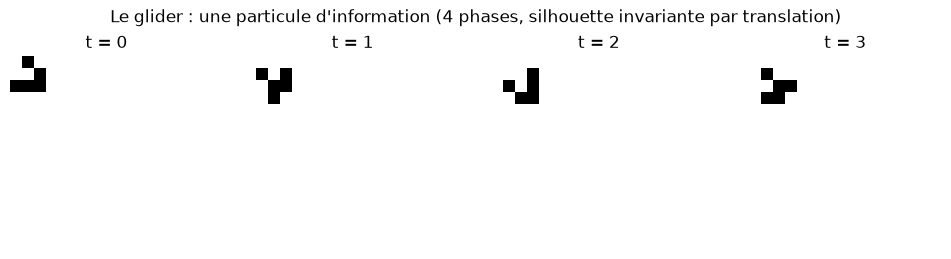

In [4]:
# Le glider comme particule d'information : periode 4, deplacement (1,1) par periode, vitesse c/4
# diagonal -- mesuree par l'organe period_and_displacement, pas affirmee.
periode, deplacement = period_and_displacement(embed(canonical_pattern("glider"), 24), max_steps=16)
vitesse = (deplacement[0] / periode, deplacement[1] / periode) if deplacement else None
attendu = CALIBRATION["glider"]

print(f"glider : periode mesurée = {periode}, déplacement par période = {deplacement}")
print(f"vitesse = ({vitesse[0]:.2f}, {vitesse[1]:.2f}) cellules/génération = c/4 diagonal")
print(f"CALIBRATION attendue : {attendu}")
assert periode == attendu["period"], "periode mesurée != constante canonique"

# Film partiel : la particule traverse sans se déformer (4 phases, meme silhouette translatee)
traj = trajectory(embed(canonical_pattern("glider"), 16), 4)
fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
for t, (ax, g) in enumerate(zip(axes, traj)):
    ax.imshow(g, cmap="binary")
    ax.set_title(f"t = {t}")
    ax.axis("off")
fig.suptitle("Le glider : une particule d'information (4 phases, silhouette invariante par translation)")
plt.tight_layout()
plt.show()

### Lecture du résultat — le cité et le mesuré, côte à côte

La cellule mesure ce que le théorème **consomme** : une particule de période 4, de vitesse $c/4$, dont la silhouette se translate sans se déformer — quatre images, une seule forme. Ce transport localisé est le **service physique** que les constructions d'universalité orchestrent (les collisions de gliders de Cook pour la règle 110, les cascades de la construction GOL). Le théorème dit que ce substrat *peut* porter tout calcul ; la mesure dit *comment le calcul y circule* : par particules, à vitesse finie, sans déformation.

**Ce que ça prouve** : la propriété « universel » est **citée avec sa source** — le carnet n'usurpe pas un théorème qu'il ne re-prouve pas — et la partie de cette universalité qui se **mesure** (l'existence et la stabilité du transporteur d'information) est établie par l'organe natif. C'est la **deuxième face** du témoin : *citée*, elle, et exactement délimitée.

## 4. La fragilité, mesurée — mêmes masses, destins opposés

Face au théorème, la contrepartie empirique : les formes qui portent le calcul s'effondrent au détail près. C'est la mesure d'ICT-33, et le capstone la consomme à son tour — par l'organe `glider_collision`, qui construit une collision contrôlée de deux gliders, et `collision_outcome`, qui lit le destin.

Le banc : **deux gliders de même masse** (chacun cinq cellules vivantes), dont on ne fait varier que l'**offset** — le décalage d'une colonne. Deux destins attendus, mesurés dans ICT-33 : l'**annihilation** (plus rien ne survit) et le **glider survivant** (une particule repart). Aucune grandeur macroscopique — masse, densité, moment — ne distingue les deux configurations : seul le détail fin tranche.

In [5]:
# Batterie de collisions : meme masse (2 gliders, 10 cellules), seul l'offset varie.
# Paires (phase, offset) calibrees sur ICT-33 section 3 ; collision_outcome rend
# {class, live, components, gliders} -- classes : annihilation / 2-gliders / 1-glider / debris.
configurations = [(0, 0, "offset 0"), (0, 8, "offset 8")]
print(f"{'configuration':<16}{'classe':>14}{'vivantes':>10}{'gliders':>9}")
for phase, offset, etiquette in configurations:
    grille = glider_collision(size=32, phase=phase, offset=offset)
    sortie = collision_outcome(grille, horizon=96)
    print(f"{etiquette:<16}{sortie['class']:>14}{sortie['live']:>10}{sortie['gliders']:>9}")

configuration           classe  vivantes  gliders
offset 0          annihilation         0        0
offset 8              1-glider        10        1


### Lecture du résultat — le destin dépend de détails que la masse ne code pas

Deux configurations **macroscopiquement identiques** — mêmes deux gliders, même masse totale, même énergie d'approche — rendent des destins opposés : à offset 0, l'intersection n'a laissé **rien** (annihilation) ; à offset 8, une particule **repart** (glider survivant). Aucune quantité agrégée (population, densité) ne sépare les deux lignes : la différence vit entière dans le **détail microscopique de l'alignement**.

C'est la mesure jumelle de la soupe d'ICT-33 : sur un moteur déterministe certifié (section 2), le bruit n'est pas dans le moteur — il est dans la **projection**, dans ce que les grandeurs macro choisissent de ne pas voir. La fragilité n'est pas un défaut du substrat : elle est **la contrepartie de son expressivité**. Un substrat dont les formes utiles résisteraient à tout alignement serait un substrat pauvre — incapable d'orchestrer les collisions fines dont la construction d'universalité (section 3) est faite.

**Ce que ça prouve** : la **troisième face** du témoin, et la seule des trois qui soit une pure **mesure** — l'extrême fragilité des formes utiles, celle qui fait du GOL un témoin exigeant et non un jouet. Universel *et* fragile : la tension des deux sections précédentes tient dans une table à deux lignes.

## 5. La lecture émergence, rejouée sur le substrat

Strate 0 jusqu'ici : les trois faces d'un témoin considéré immobile. Mais le GOL n'est pas qu'un objet à certifier — ICT-32 a montré qu'il expose déjà une **hiérarchie causale mesurable**, celle-là même que les strates hautes de la série explorent. Le capstone rejoue la mesure centrale par les organes natifs : la TPM déterministe de B3/S23 sur **l'ensemble exhaustif** des graines du tore 3×3 (512 états), puis deux manières de regrouper ces états en macro — par **destin** (les fibres de la fonction successeur : deux graines qui évoluent vers la même grille) et par **population** (le nombre de cellules vivantes, l'observable macro « naturelle »). La batterie `ict.causal_emergence` mesure laquelle des deux partitions suit la structure causale de la règle.

In [6]:
# La question de Hoel sur le substrat certifie : une macro bat-elle le micro ?
# TPM deterministe de B3/S23 sur TOUTES les graines du tore 3x3 (512 etats),
# puis deux partitions : par destin (fibres du successeur) vs par population.
from ict.causal_emergence import causal_profile, partition_profile, greedy_apportionment
from ict.life import torus_ensemble_tpm, fate_strata, live_count_strata

tpm3, succ3 = torus_ensemble_tpm(3)
micro = causal_profile(tpm3)
fate = partition_profile(tpm3, fate_strata(succ3))
pop = partition_profile(tpm3, live_count_strata(3, succ3))
print(f"{'partition':<26}{'etats':>7}{'effectiveness':>15}")
print(f"{'micro (aucune)':<26}{512:>7}{micro['effectiveness']:>15.3f}")
print(f"{'par destin':<26}{len(fate_strata(succ3)):>7}{fate['effectiveness']:>15.3f}")
print(f"{'par population':<26}{len(live_count_strata(3, succ3)):>7}{pop['effectiveness']:>15.3f}")

# Le glouton, sur le tore 2x2 (16 etats) : re-derive-t-il la partition par destin ?
tpm2, _ = torus_ensemble_tpm(2)
res = greedy_apportionment(tpm2)
print(f"\nglouton 2x2 : {res['scales'][0]['size']} -> {res['scales'][-1]['size']} etats, "
      f"effectiveness {res['scales'][0]['effectiveness']:.3f} -> {res['scales'][-1]['effectiveness']:.3f}, "
      f"EC = {res['emergent_complexity']:.2f}")

partition                   etats  effectiveness
micro (aucune)                512          0.344
par destin                    128          0.998
par population                 10          0.278



glouton 2x2 : 16 -> 5 etats, effectiveness 0.328 -> 1.000, EC = 6.70


### Lecture du résultat — le destin bat, la population ne suit pas

Quatre lignes, un contraste net. La partition **par destin** regroupe les 512 graines en 128 fibres et **restaure** l'effectiveness (0.344 → 0.998) : regrouper les états qui ont le même avenir ne perd aucune cause — la macro suit la structure causale de la règle. La partition **par population** — l'observable macro « naturelle » — fait pire que le micro (0.278) : B3/S23 mélange croissance et mort au sein d'une même strate de population, et le regroupement détruit de l'information causale. Et le glouton, qui **cherche** la meilleure fusion sans qu'on lui souffle la partition, re-dérive exactement le squelette par destin : 16 → 5 états sur le tore 2×2, effectiveness terminale 1.000, EC = 6.70 — le travail causal distribué le long des échelles plutôt qu'un saut unique.

**Ce que ça prouve** : même le substrat minimal n'est pas causalement plat — la hiérarchie micro/macro que les strates hautes de la série explorent est déjà **mesurable à la strate 0**, sur un moteur déterministe certifié (section 2). ICT-32 pousse la mesure plus loin (strate phase du glider causalement étanche, EC = 0 structurel de la trajectoire isolée) ; le capstone n'a fait que la rejouer par les organes natifs — c'est le pont de la strate 0 vers le reste de la série.

## 6. Le témoin parmi les substrats — pourquoi le GOL

Universalité citée (§3), fragilité mesurée (§4), certification prouvée (§2) : trois propriétés que le GOL **réunit**. Sont-elles rares ? ICT-31 a passé trois substrats au même banc, sur trois axes — transport (T), robustesse (R), enjeu (S) — et son profil mesuré répond :

| | S2 (bistable) | S5 (Gray-Scott) | GOL (B3/S23) |
|---|---|---|---|
| **Mode** | effacer | régénérer | **transporter** |
| **L'information survit…** | comme un bit (bassin choisi) | en se recollant sur place | **en étant ailleurs** |
| **Faiblesse mesurée** | aucun espace | immobile | **fragile à l'impact direct** |
| **Instrument qui la voit** | I_stake ✓ | I_stake + recovery ✓ | period/displacement ✓ — I_stake ✗ |

La lecture se fait en colonnes : chaque substrat est un **mode de relation à l'information**, aucun n'est « meilleur » dans l'absolu. Mais deux lignes fondent le choix du témoin. L'axe T d'abord : le GOL est le **seul transporteur localisé** du banc — et ce transport, la section 3 l'a re-mesuré (glider c/4, silhouette invariante par translation). L'instrument ensuite : `I_stake`, conçu pour les bassins, est **aveugle aux invariants translationnels** — la « défense » d'un glider serait de rester *une forme qui bouge*, pas de revenir *à une place*. Mesurer un substrat translatif avec une ancre de bassin, c'est pointer un thermomètre sur la lumière.

**Ce que ça prouve** : le GOL n'est pas témoin parce qu'il « gagnerait » — il est le seul à réunir **transport localisé** (le service que l'universalité consomme, §3), **certification disponible** (le pont Lean, §2) et **fragilité documentée** (la contrepartie mesurée, §4). Un substrat qui transporte sans être certifiable, ou certifiable mais immobile, ne porterait pas les trois faces. Et la fragilité elle-même n'est pas disqualifiante : elle est le prix de l'expressivité (§4) — un témoin exigeant, pas un jouet.

## 7. Synthèse — les trois faces du témoin

| Face | Statut épistémique | Où elle vit | Le contre-pied |
|---|---|---|---|
| **Certifié** | **prouvé** (Lean 4, non-vacuous) | `evolveHashlifeFastAtN_correct_uncond` — re-mesuré §2 | `hashlife_correct` est vrai… par vacuité |
| **Universel** | **cité** (Cook 2004 ; construction BCG 1982) | jamais re-prouvé — §3 délimite ce que le carnet mesure | la mesure honnête porte le **transport** (c/4), pas le théorème |
| **Fragile** | **mesuré** (organe `glider_collision`) | mêmes masses, destins opposés — §4 | la fragilité est le **prix de l'expressivité**, pas un défaut |

Trois statuts **distincts** — preuve, citation, mesure — tenus ensemble par un seul substrat : c'est la définition opérationnelle du témoin de strate 0. Les fils rouges pour la suite :

- **ICT-15k** (*Recollement macro-cells*) : l'espace étalé du moteur quadtree dont la section 2 certifie l'égalité avec le naïf ;
- **ICT-48 / Complexity-08** (*classes de Wolfram*, *Rule 30 / Rule 110* — l'ex-ICT-50, parti vers Complexity) : la classification empirique dont la règle 110 de Cook est le pivot d'universalité — le modèle d'honnêteté « cité, jamais re-prouvé » que la section 3 applique ;
- **Capstone 21** (terminal) : consomme le même organe `ict/life.py` et le même pont — ce que la strate 0 certifie ici y devient matière à trajet.

Le GOL ouvre la lecture ICT non pas comme un automate parmi d'autres, mais comme le **substrat sur lequel la série entière s'appuie** : chaque strate haute hérite de la garantie de preuve de la section 2, du service de transport de la section 3 et de la leçon de fragilité de la section 4.

## Exercices

Trois exercices, chacun étend une mesure réelle du carnet — jamais à côté. Les organes sont déjà importés ; il suffit de les orchestrer.

In [7]:
# Exercice 1 -- Table des destins d'une famille de collisions.
# La section 4 ne mesure que DEUX offsets ; etendre le balayage a une famille
# (phase, offset) et rendre la table des destins. Extension mesuree de l'exercice 1 d'ICT-33.

def table_offsets(phases, offsets):
    # Etape 1 : pour chaque paire (phase, offset), construire la grille par glider_collision(size=32, phase=phase, offset=offset)
    # Etape 2 : lire le destin par collision_outcome(grille, horizon=96)
    # Etape 3 : rendre un dict {(phase, offset): classe} -- ou une table imprimee
    # TODO etudiant
    # Indice : la cellule de la section 4 fait exactement ce geste pour deux paires ; il suffit de boucler et de collecter.
    return None  # TODO etudiant

print("Exercice 1 a completer : table des destins d'une famille de collisions glider-glider")
print(table_offsets([0, 2], [0, 4, 8]))

Exercice 1 a completer : table des destins d'une famille de collisions glider-glider
None


In [8]:
# Exercice 2 -- Le certificat vivant, re-mesure sur un pattern de votre choix.
# L'egalite Hashlife <-> naif vit dans Lean (section 2, citee) ; les DEUX jambes python du
# pont se re-mesurent : (a) le verdict de calibration du pattern, (b) l'invariance de sa
# periode par la taille d'encastrement. Consomme la machinerie du pont (ICT-Life c19-21).

def certificat_vivant(pattern, tailles=(24, 32, 48)):
    # Etape 1 : verdict de calibration -- calibrate(pattern) doit rendre (True, constantes)
    # Etape 2 : pour chaque taille, embed(canonical_pattern(pattern), taille) puis period_and_displacement
    # Etape 3 : rendre (verdict, {taille: periode}) -- les periodes doivent coincider
    # TODO etudiant
    # Indice : importez calibrate en tete de cellule (from ict.life import calibrate) ; comparez a CALIBRATION[pattern]["period"].
    return None  # TODO etudiant

print("Exercice 2 a completer : le certificat vivant, re-mesure (calibration + periode invariante)")
print(certificat_vivant("glider"))

Exercice 2 a completer : le certificat vivant, re-mesure (calibration + periode invariante)
None


In [9]:
# Exercice 3 -- Densite de transporteurs dans une soupe.
# A quelle densite initiale les soupes produisent-elles des gliders ? Relie la propriete
# citee (l'universalite CONSOMME des transporteurs, section 3) et la propriete mesuree
# (la fragilite qui les menace, section 4). Materiau : les soupes seuil d'ICT-33.

def densite_transporteurs(densites, par_densite=40, horizon=96, seed=5726):
    # Etape 1 : pour chaque densite, tirer par_densite soupes random_soup(32, densite, rng)
    # Etape 2 : faire evoluer chaque soupe horizon generations (next_generation en boucle)
    # Etape 3 : compter les soupes dont le destin contient au moins un glider (connected_components + is_glider)
    # Etape 4 : rendre {densite: taux} -- le taux de soupes porteuses d'au moins un glider
    # TODO etudiant
    # Indice : une rng par densite (default_rng(seed + int(densite * 1000))) evite de re-tirer la meme soupe.
    return None  # TODO etudiant

print("Exercice 3 a completer : taux de soupes produisant au moins un glider, par densite initiale")
print(densite_transporteurs([0.2, 0.35, 0.5]))

Exercice 3 a completer : taux de soupes produisant au moins un glider, par densite initiale
None


## À retenir

- **Trois faces, trois statuts épistémiques** — le GOL est **certifié** (théorème Lean non-vacuous, re-mesuré par l'instrument canonique), **universel** (théorème *cité* avec sa source — Cook 2004 pour la règle 110, construction BCG 1982 pour Life), **fragile** (destins opposés à masse égale, *mesuré* par l'organe `glider_collision`). Ne jamais confondre les trois : c'est le fil rouge d'honnêteté du capstone.
- **Le certificat est vivant** — pas une relique : calibration 5/5 + `sorry` réels = 0 se re-mesurent en trois cellules, par `count_code_sorry.py` (jamais un `grep -c sorry`, qui compte la prose).
- **Le glider est le service physique de l'universalité** — transport localisé à c/4, silhouette invariante : ce que les constructions d'universalité consomment, et ce que la section 3 mesure *à côté* du théorème.
- **La fragilité est le prix de l'expressivité** — offset 0 annihile, offset 8 laisse repartir un glider : aucun agrégat macroscopique ne sépare les deux lignes. Le bruit n'est pas dans le moteur (certifié), il est dans la projection.
- **Même la strate 0 est causalement structurée** — la partition par destin restaure l'effectiveness (0.998), la partition par population la détruit (0.278), et le glouton re-dérive la première sans qu'on la lui souffle : le pont vers ICT-32 et les strates hautes.
- **Témoin, pas champion** — ICT-31 : le GOL est le seul des trois substrats à transporter l'information *ailleurs* ; son instrument dédié est `period_and_displacement`, pas `I_stake` — chaque instrument a ses aveugles.

## Vérifiez votre compréhension

1. Pourquoi le capstone cite-t-il Cook (2004) au lieu de re-prouver l'universalité — et que mesure-t-il *à la place*, exactement ?
2. `hashlife_correct` est vrai et pourtant la section 2 ne s'appuie pas sur lui : quelle est la différence précise avec `evolveHashlifeFastAtN_correct_uncond` ?
3. Deux collisions de gliders de même masse rendent « annihilation » et « 1-glider survivant » : citez une grandeur macroscopique qui ne peut PAS les distinguer, et dites où vit la différence.
4. Sur le tore 3×3, la partition par population fait *pire* que le micro : quel geste de la règle B3/S23 l'explique ?
5. `I_stake` ne voit pas le glider : quel type d'invariant faudrait-il mesurer à la place, et pourquoi ?

***

**Références** — Cook, M. (2004). *Universality in Elementary Cellular Automata*. Complex Systems 15(1), 1-40. — Berlekamp, E., Conway, J. H., & Guy, R. (1982). *Winning Ways for Your Mathematical Plays*, vol. 2, ch. 25 « What is Life? ». — Gardner, M. (1970). *Mathematical Games*. Scientific American 223(4). — Hoel, E. (2013). *When the Map Is Better Than the Territory*. Entropy 15(6). — Rendell, P. (2000, page web ; 2001, papier). *A Turing Machine in Conway's Game of Life*.

**Module** : `ict/life.py`, `ict/causal_emergence.py`, `scripts/lean/count_code_sorry.py` — **Notebook pédagogique** : des exercices jalonnent le texte.

**Navigation** : [Index](README.md) | Suivant : [ICT-1 — Trajectoires de $\Phi$](ICT-01-PhiTrajectories-Python.ipynb) | Parents : [ICT-Life](ICT-Life-SubstratCertifie-Python.ipynb) · [ICT-31](ICT-31-ContrasteTroisSubstrats-Python.ipynb) · [ICT-32](ICT-32-StratificationCausaleLife-Python.ipynb) · ICT-33